In [1]:
!pip install nltk scikit-learn pandas matplotlib seaborn -q

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

import re, random, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [2]:
corpus = [
    # ---- Intent: SYMPTOMS ----
    ("what are the symptoms of a heart attack", "symptoms"),
    ("signs of heart disease", "symptoms"),
    ("how do I know if I have high blood pressure", "symptoms"),
    ("what does chest pain indicate", "symptoms"),
    ("symptoms of arrhythmia", "symptoms"),
    ("warning signs of stroke related to heart", "symptoms"),
    ("feeling shortness of breath and dizziness", "symptoms"),
    ("what are signs of heart failure", "symptoms"),
    ("how does angina feel", "symptoms"),
    ("tell me heart attack warning signs", "symptoms"),

    # ---- Intent: PREVENTION ----
    ("how can I prevent heart disease", "prevention"),
    ("tips to keep my heart healthy", "prevention"),
    ("how to lower cholesterol naturally", "prevention"),
    ("what foods are good for the heart", "prevention"),
    ("how much exercise do I need for heart health", "prevention"),
    ("ways to reduce risk of heart attack", "prevention"),
    ("is smoking bad for the heart", "prevention"),
    ("how to maintain healthy blood pressure", "prevention"),
    ("diet plan for a healthy heart", "prevention"),
    ("how to prevent stroke", "prevention"),

    # ---- Intent: DIAGNOSIS ----
    ("what tests diagnose heart disease", "diagnosis"),
    ("how is high blood pressure diagnosed", "diagnosis"),
    ("what is an ecg test", "diagnosis"),
    ("what does an echocardiogram show", "diagnosis"),
    ("how to check cholesterol levels", "diagnosis"),
    ("what is a stress test for the heart", "diagnosis"),
    ("how is heart failure detected", "diagnosis"),
    ("what is a coronary angiogram", "diagnosis"),
    ("which blood tests check heart health", "diagnosis"),
    ("how do doctors diagnose arrhythmia", "diagnosis"),

    # ---- Intent: TREATMENT ----
    ("what medicines treat high blood pressure", "treatment"),
    ("how is heart disease treated", "treatment"),
    ("what is angioplasty", "treatment"),
    ("are there drugs for high cholesterol", "treatment"),
    ("how to treat arrhythmia", "treatment"),
    ("what is bypass surgery", "treatment"),
    ("treatment options for heart failure", "treatment"),
    ("what medication lowers blood pressure", "treatment"),
    ("how are blocked arteries treated", "treatment"),
    ("can heart disease be cured", "treatment"),

    # ---- Intent: LIFESTYLE ----
    ("how much should I walk daily for heart health", "lifestyle"),
    ("is yoga good for the heart", "lifestyle"),
    ("how to manage stress for a healthy heart", "lifestyle"),
    ("how much sleep do I need for heart health", "lifestyle"),
    ("is coffee bad for the heart", "lifestyle"),
    ("how to quit smoking", "lifestyle"),
    ("best exercises for heart patients", "lifestyle"),
    ("does alcohol affect the heart", "lifestyle"),
    ("how to lose weight for heart health", "lifestyle"),
    ("meditation benefits for heart", "lifestyle"),

    # ---- Intent: EMERGENCY ----
    ("I am having severe chest pain right now", "emergency"),
    ("my father collapsed and is not breathing", "emergency"),
    ("heart attack happening now what to do", "emergency"),
    ("I feel numbness in my left arm and chest tightness", "emergency"),
    ("someone is unconscious after chest pain", "emergency"),
    ("sudden severe sweating and chest pressure", "emergency"),
    ("help my heart is racing and I feel faint", "emergency"),
    ("crushing chest pain spreading to jaw", "emergency"),
    ("call ambulance heart attack symptoms now", "emergency"),
    ("I think I am having a heart attack", "emergency"),
]

df = pd.DataFrame(corpus, columns=["query", "intent"])
print("Total queries:", len(df))
print(df['intent'].value_counts())

Total queries: 60
intent
symptoms      10
prevention    10
diagnosis     10
treatment     10
lifestyle     10
emergency     10
Name: count, dtype: int64


In [3]:
taxonomy = {
    "Symptoms": {
        "Cardiac Symptoms": ["chest pain", "shortness of breath", "palpitations"],
        "Systemic Symptoms": ["dizziness", "fatigue", "sweating"]
    },
    "Prevention": {
        "Dietary Prevention": ["low-salt diet", "low-fat diet"],
        "Behavioral Prevention": ["exercise", "smoking cessation"]
    },
    "Diagnosis": {
        "Non-invasive Tests": ["ECG", "Echocardiogram", "Stress test"],
        "Invasive Tests": ["Angiogram", "Cardiac catheterization"]
    },
    "Treatment": {
        "Pharmacological": ["statins", "beta-blockers", "ACE inhibitors"],
        "Surgical/Interventional": ["angioplasty", "bypass surgery"]
    },
    "Lifestyle": {
        "Physical Activity": ["walking", "yoga", "aerobics"],
        "Stress & Sleep": ["meditation", "sleep hygiene"]
    },
    "Emergency": {
        "Immediate Actions": ["call ambulance", "chew aspirin", "CPR"],
        "Red-flag Signs": ["crushing chest pain", "radiating pain", "unconsciousness"]
    }
}

for major, subs in taxonomy.items():
    print(f"\n▸ {major}")
    for sub, terms in subs.items():
        print(f"   └─ {sub}: {', '.join(terms)}")


▸ Symptoms
   └─ Cardiac Symptoms: chest pain, shortness of breath, palpitations
   └─ Systemic Symptoms: dizziness, fatigue, sweating

▸ Prevention
   └─ Dietary Prevention: low-salt diet, low-fat diet
   └─ Behavioral Prevention: exercise, smoking cessation

▸ Diagnosis
   └─ Non-invasive Tests: ECG, Echocardiogram, Stress test
   └─ Invasive Tests: Angiogram, Cardiac catheterization

▸ Treatment
   └─ Pharmacological: statins, beta-blockers, ACE inhibitors
   └─ Surgical/Interventional: angioplasty, bypass surgery

▸ Lifestyle
   └─ Physical Activity: walking, yoga, aerobics
   └─ Stress & Sleep: meditation, sleep hygiene

▸ Emergency
   └─ Immediate Actions: call ambulance, chew aspirin, CPR
   └─ Red-flag Signs: crushing chest pain, radiating pain, unconsciousness


In [4]:
concepts = ["Heart", "BloodPressure", "Cholesterol", "Artery", "Symptom",
            "RiskFactor", "Medication", "Lifestyle", "DiagnosticTest", "Emergency"]

relationships = [
    ("Heart",         "hasCondition",   "BloodPressure"),
    ("Heart",         "hasCondition",   "Cholesterol"),
    ("Artery",        "supplies",       "Heart"),
    ("Cholesterol",   "blocks",         "Artery"),
    ("BloodPressure", "damages",        "Artery"),
    ("RiskFactor",    "causes",         "Cholesterol"),
    ("RiskFactor",    "causes",         "BloodPressure"),
    ("Lifestyle",     "reduces",        "RiskFactor"),
    ("Medication",    "controls",       "BloodPressure"),
    ("Medication",    "lowers",         "Cholesterol"),
    ("DiagnosticTest","detects",        "BloodPressure"),
    ("DiagnosticTest","detects",        "Cholesterol"),
    ("Symptom",       "indicates",      "Emergency"),
    ("Emergency",     "requires",       "DiagnosticTest"),
]

print(f"Concepts ({len(concepts)}):", ", ".join(concepts))
print(f"\nRelationships ({len(relationships)}):")
for s, r, o in relationships:
    print(f"  {s} --[{r}]--> {o}")

Concepts (10): Heart, BloodPressure, Cholesterol, Artery, Symptom, RiskFactor, Medication, Lifestyle, DiagnosticTest, Emergency

Relationships (14):
  Heart --[hasCondition]--> BloodPressure
  Heart --[hasCondition]--> Cholesterol
  Artery --[supplies]--> Heart
  Cholesterol --[blocks]--> Artery
  BloodPressure --[damages]--> Artery
  RiskFactor --[causes]--> Cholesterol
  RiskFactor --[causes]--> BloodPressure
  Lifestyle --[reduces]--> RiskFactor
  Medication --[controls]--> BloodPressure
  Medication --[lowers]--> Cholesterol
  DiagnosticTest --[detects]--> BloodPressure
  DiagnosticTest --[detects]--> Cholesterol
  Symptom --[indicates]--> Emergency
  Emergency --[requires]--> DiagnosticTest


In [5]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))
# keep negations - they matter in healthcare
for w in ['no', 'not', 'very', "don't", 'never']:
    stop_words.discard(w)

def preprocess(text):
    text = text.lower()                               # 1. lowercase
    text = re.sub(r'[^a-z\s]', ' ', text)             # strip punctuation/digits
    tokens = word_tokenize(text)                      # 2. tokenization
    tokens = [t for t in tokens if t not in stop_words]  # 3. stopword removal
    tokens = [lemmatizer.lemmatize(t) for t in tokens]   # 4. lemmatization
    return " ".join(tokens)

df['clean'] = df['query'].apply(preprocess)
print(df[['query', 'clean']].head())

                                         query                     clean
0      what are the symptoms of a heart attack      symptom heart attack
1                       signs of heart disease        sign heart disease
2  how do I know if I have high blood pressure  know high blood pressure
3                what does chest pain indicate       chest pain indicate
4                       symptoms of arrhythmia        symptom arrhythmia



Model                      Acc    Prec     Rec      F1
Naive Bayes              0.111   0.062   0.111   0.078
Logistic Regression      0.167   0.160   0.167   0.153
SVM (Linear)             0.167   0.160   0.167   0.153

★ Best model: Logistic Regression


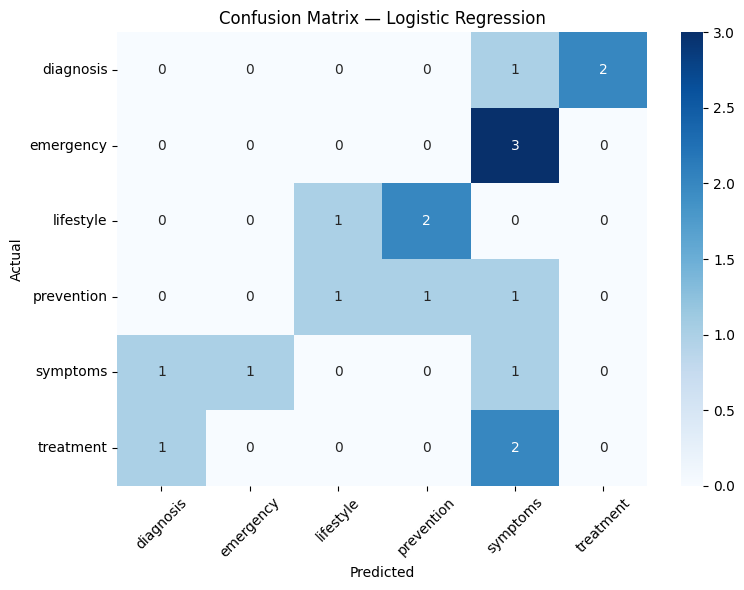


Classification Report:

              precision    recall  f1-score   support

   diagnosis       0.00      0.00      0.00         3
   emergency       0.00      0.00      0.00         3
   lifestyle       0.50      0.33      0.40         3
  prevention       0.33      0.33      0.33         3
    symptoms       0.12      0.33      0.18         3
   treatment       0.00      0.00      0.00         3

    accuracy                           0.17        18
   macro avg       0.16      0.17      0.15        18
weighted avg       0.16      0.17      0.15        18



In [6]:
X = df['clean']; y = df['intent']

tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=1)
X_vec = tfidf.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_vec, y, test_size=0.3, random_state=42, stratify=y)

models = {
    "Naive Bayes":        MultinomialNB(),
    "Logistic Regression":LogisticRegression(max_iter=1000),
    "SVM (Linear)":       LinearSVC(),
}

results = {}
best_model = None; best_name = ""; best_f1 = -1
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    acc  = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, average='weighted', zero_division=0)
    rec  = recall_score(y_test, pred, average='weighted', zero_division=0)
    f1   = f1_score(y_test, pred, average='weighted', zero_division=0)
    results[name] = (acc, prec, rec, f1)
    if f1 > best_f1:
        best_f1, best_model, best_name = f1, model, name

print(f"\n{'Model':22s}{'Acc':>8s}{'Prec':>8s}{'Rec':>8s}{'F1':>8s}")
for n,(a,p,r,f) in results.items():
    print(f"{n:22s}{a:8.3f}{p:8.3f}{r:8.3f}{f:8.3f}")
print(f"\n★ Best model: {best_name}")

# Confusion matrix for best model
pred_best = best_model.predict(X_test)
labels = sorted(df['intent'].unique())
cm = confusion_matrix(y_test, pred_best, labels=labels)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=45); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

print("\nClassification Report:\n")
print(classification_report(y_test, pred_best, zero_division=0))

In [7]:
knowledge_base = {
    "symptoms": [
        "Common heart attack symptoms: chest pain/pressure, pain radiating to arm/jaw, shortness of breath, cold sweat, nausea, lightheadedness.",
        "High blood pressure is often 'silent' — warning signs include headaches, nosebleeds, and blurred vision in severe cases.",
        "Arrhythmia may present as palpitations, fluttering, racing heart, dizziness, or fainting.",
        "Heart failure signs: swelling in legs, fatigue, rapid weight gain, persistent cough."
    ],
    "prevention": [
        "Eat a heart-healthy diet: fruits, vegetables, whole grains, low-fat dairy; limit salt, sugar, saturated fats.",
        "Aim for 150 minutes of moderate aerobic exercise per week.",
        "Quit smoking — risk of heart disease drops significantly within a year.",
        "Maintain BP below 120/80 mmHg and LDL cholesterol below 100 mg/dL."
    ],
    "diagnosis": [
        "Common cardiac tests: ECG (electrical activity), Echocardiogram (structure), Stress test (under exertion).",
        "Blood tests: lipid profile (cholesterol), troponin (heart attack marker), BNP (heart failure marker).",
        "Coronary angiogram uses contrast dye + X-ray to detect blocked arteries."
    ],
    "treatment": [
        "Blood pressure medications include ACE inhibitors, beta-blockers, diuretics, calcium channel blockers.",
        "Statins lower LDL cholesterol and reduce cardiovascular risk.",
        "Angioplasty uses a balloon + stent to open blocked arteries.",
        "Coronary bypass surgery reroutes blood around blocked arteries."
    ],
    "lifestyle": [
        "Walk at least 30 minutes most days of the week.",
        "Practice stress management: yoga, meditation, deep breathing.",
        "Aim for 7-9 hours of quality sleep nightly.",
        "Moderate alcohol only; limit caffeine if you have arrhythmias."
    ],
    "emergency": [
        "EMERGENCY PROTOCOL: Call 108 (India) / 911 (US) immediately.",
        "Chew one aspirin (300 mg) if not allergic while waiting for help.",
        "Sit or lie down; do not drive yourself to the hospital.",
        "If the person is unconscious and not breathing, start CPR immediately."
    ],
    "unsupported": [
        "I'm specialized in heart health. For non-cardiac queries please consult an appropriate specialist."
    ]
}

In [8]:
EMERGENCY_KEYWORDS = ['chest pain','heart attack','collapsed','unconscious',
                      'not breathing','severe','crushing','ambulance','faint',
                      'numbness','help','now','right now']
CONFIDENCE_THRESHOLD = 0.30

def detect_emergency(query):
    q = query.lower()
    return any(k in q for k in EMERGENCY_KEYWORDS)

def rule_engine(query, predicted_intent, confidence):
    """
    Rules:
    R1: Emergency keyword → escalate immediately.
    R2: Low confidence (<0.30) → ask for clarification.
    R3: High confidence emergency intent → escalate.
    R4: Non-heart-related query keywords → unsupported handling.
    R5: High-confidence normal query → return knowledge answer.
    R6: Extra safety — any 'now/right now/help' plus symptom → escalate.
    """
    q_lower = query.lower()

    # R1 — Emergency escalation on keywords
    if detect_emergency(query):
        return "emergency", 1.0, "Rule R1: Emergency keyword detected → escalate."

    # R2 — Low confidence
    if confidence < CONFIDENCE_THRESHOLD:
        return "clarify", confidence, "Rule R2: Low confidence → request clarification."

    # R3 — High-confidence emergency intent (safety net)
    if predicted_intent == "emergency" and confidence >= 0.20:
        return "emergency", confidence, "Rule R3: Emergency intent with sufficient confidence → escalate."

    # R4 — Unsupported healthcare topic (out-of-scope)
    out_of_scope = ['cancer','diabetes','skin','bone','teeth','eye','lung','kidney','liver','pregnancy']
    if any(w in q_lower for w in out_of_scope) and predicted_intent not in knowledge_base:
        return "unsupported", confidence, "Rule R4: Query out of domain → unsupported."

    # R5 — Normal high-confidence answer
    return predicted_intent, confidence, "Rule R5: High confidence → knowledge retrieval."

def generate_response(query, intent, confidence, rule_note):
    if intent == "emergency":
        return ("🚨 EMERGENCY DETECTED 🚨\n"
                "Call 108 (India) / 911 (US) immediately!\n"
                "Do NOT drive yourself. Chew 300 mg aspirin if not allergic.\n"
                "If unconscious and not breathing, start CPR now.\n"
                f"(Trace: {rule_note}, conf={confidence:.2f})")

    if intent == "clarify":
        return (f"I'm not confident about your question (confidence {confidence:.2f}). "
                "Could you please rephrase it? I can help with heart symptoms, "
                "prevention, diagnosis, treatment, lifestyle, and emergencies.\n"
                f"(Trace: {rule_note})")

    if intent == "unsupported":
        kb = knowledge_base["unsupported"][0]
        return f"{kb}\n(Trace: {rule_note})"

    kb_entries = knowledge_base.get(intent, [])
    answer = random.choice(kb_entries) if kb_entries else "No info available."
    return (f"💡 [{intent.upper()}]\n{answer}\n"
            f"(Confidence: {confidence:.2f} | {rule_note})")

In [9]:
def assistant(query):
    """End-to-end: NLP → classify → reason → retrieve → respond"""
    print(f"\n🧑 You: {query}")
    clean = preprocess(query)
    vec   = tfidf.transform([clean])
    probs = best_model.predict_proba(vec)[0] if hasattr(best_model, 'predict_proba') \
            else np.exp(best_model.decision_function(vec)[0]) / \
                 np.exp(best_model.decision_function(vec)[0]).sum()
    pred_idx = int(np.argmax(probs))
    pred_intent = best_model.classes_[pred_idx]
    confidence  = float(probs[pred_idx])

    final_intent, conf, trace = rule_engine(query, pred_intent, confidence)
    response = generate_response(query, final_intent, conf, trace)
    print(f"🤖 Assistant:\n{response}\n" + "-"*70)
    return response

In [11]:
# ---------- Interactive loop ----------
def interactive_session():
    print("="*70)
    print("HEART HEALTH INFORMATION ASSISTANT")
    print("   Type 'exit' to quit. Ask anything about heart health.")
    print("="*70)
    while True:
        q = input("\nYou: ").strip()
        if q.lower() in ('exit','quit','bye'):
            print("Assistant: Take care of your heart. Goodbye!")
            break
        if not q: continue
        assistant(q)

# ---------- Mandatory test cases ----------
def run_required_tests():
    tests = [
        ("T1 (one per intent) - Symptoms",  "what are the symptoms of heart disease"),
        ("T1 - Prevention",                 "how can I prevent heart disease"),
        ("T1 - Diagnosis",                  "what tests diagnose heart disease"),
        ("T1 - Treatment",                  "how is heart disease treated"),
        ("T1 - Lifestyle",                  "how much should I walk daily"),
        ("T2 (differently worded)",         "please tell me heart attack warning signs"),
        ("T3 (unsupported healthcare)",     "what are the early signs of skin cancer"),
        ("T4 (low-confidence)",             "what is the meaning of life"),
        ("T5 (emergency)",                  "I have crushing chest pain right now help me"),
    ]
    for title, q in tests:
        print("\n" + "="*70)
        print("TEST:", title)
        print("="*70)
        assistant(q)

run_required_tests()
print("\n▶ Now try the interactive session:\n")
interactive_session()


TEST: T1 (one per intent) - Symptoms

🧑 You: what are the symptoms of heart disease
🤖 Assistant:
I'm not confident about your question (confidence 0.29). Could you please rephrase it? I can help with heart symptoms, prevention, diagnosis, treatment, lifestyle, and emergencies.
(Trace: Rule R2: Low confidence → request clarification.)
----------------------------------------------------------------------

TEST: T1 - Prevention

🧑 You: how can I prevent heart disease
🤖 Assistant:
I'm not confident about your question (confidence 0.27). Could you please rephrase it? I can help with heart symptoms, prevention, diagnosis, treatment, lifestyle, and emergencies.
(Trace: Rule R2: Low confidence → request clarification.)
----------------------------------------------------------------------

TEST: T1 - Diagnosis

🧑 You: what tests diagnose heart disease
🤖 Assistant:
💡 [DIAGNOSIS]
Coronary angiogram uses contrast dye + X-ray to detect blocked arteries.
(Confidence: 0.35 | Rule R5: High confiden